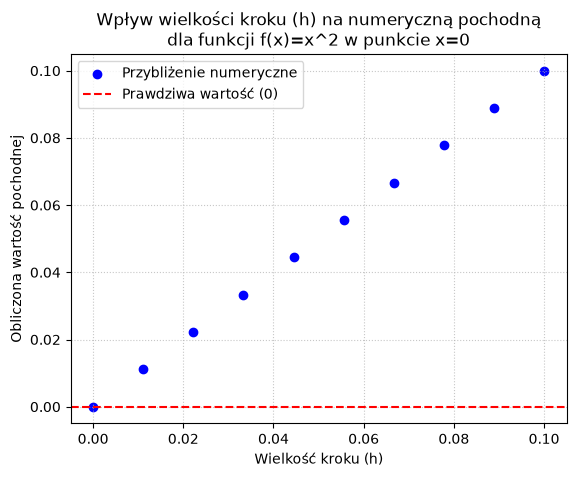

In [10]:
import numpy as np
import matplotlib.pyplot as plt

def difference_qoutient(f, x, h):
    return (f(x + h) - f(x)) / h

# sprawdzenie ze dziala
def check(f, X):
    H = np.linspace(0.00001, 0.1, 10)
    diffs_numerical = [difference_qoutient(f,x,H) for x in X]
    acc_diif = [2*x for x in X]
    err = [diffs_numerical[i] - acc_diif[i] for i in range(len(acc_diif))]
    return err, diffs_numerical, acc_diif

H_values = np.linspace(0.00001, 0.1, 10)
numerical_diffs_at_0 = check(lambda x: x**2, [0, 2, 10])[1][0]

plt.scatter(H_values, numerical_diffs_at_0, color='blue', label='Przybliżenie numeryczne')

plt.axhline(y=0, color='red', linestyle='--', label='Prawdziwa wartość (0)')

plt.title('Wpływ wielkości kroku (h) na numeryczną pochodną\ndla funkcji f(x)=x^2 w punkcie x=0')
plt.xlabel('Wielkość kroku (h)')
plt.ylabel('Obliczona wartość pochodnej')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

In [ ]:
def partial_diff(f, v, i, h):
    v_h = [v_j + (h if j == i else 0) for j, v_j in enumerate(v)]
    return (f(v_h) - f(v)) / h

In [ ]:
import random
def grad_step(v, grad, step_size):
    step = step_size * np.array(grad)
    return np.array(v) + step
def grad(v):
    return [2*x for x in v]

v = np.random.uniform(-10,10,3)
for epoch in range(100):
    print(epoch, v)
    v = grad_step(v, grad(v), -0.01)


In [69]:
# funkcja do regresji liniowej za pomoca gradient decent 
inputs = [(x, x*20 + 5) for x in range(-50, 50)]
def linear_grad(x, y, coef):
    a, b = coef
    y_pred = a*x + b 
    err = y_pred - y
    grad = [2 * err * x, 2*err] # pochodne czastkowe funkcji bledu wzgledem a i b 
    return grad

v_start = np.random.uniform(-1, 1, 2)

learning_rate = 0.001
for epoch, i in enumerate(range(5_000)):
    grad = np.mean([linear_grad(x,y, v_start) for x,y in inputs], axis=0)
    v_start = grad_step(v_start, grad, -learning_rate)
    if i % 500 == 0:
        print(epoch, v_start, grad) 

0 [33.78563176  0.2931355 ] [-3.44607852e+04  1.12839924e+01]
500 [19.99896258  3.27269814] [-2.07836873e-03 -3.46048519e+00]
1000 [19.99961862  4.36500608] [-7.64053769e-04 -1.27214999e+00]
1500 [19.9998598   4.76656236] [-2.80882863e-04 -4.67670141e-01]
2000 [19.99994846  4.91418322] [-1.03258685e-04 -1.71925765e-01]
2500 [19.99998105  4.96845188] [-3.79601479e-05 -6.32036690e-02]
3000 [19.99999303  4.98840222] [-1.39549838e-05 -2.32350501e-02]
3500 [19.99999744  4.9957364 ] [-5.13015777e-06 -8.54171226e-03]
4000 [19.99999906  4.99843261] [-1.88596026e-06 -3.14012012e-03]
4500 [19.99999965  4.99942379] [-6.93316165e-07 -1.15437679e-03]


In [74]:
# minibatch i stochastic grad dec

def minibatch(ds, batch_size):
    batch_starts = [start for start in range(0, len(ds), batch_size)]
    random.shuffle(batch_starts)
    for start in batch_starts:
        end = start + batch_size
        yield ds[start:end]

v_start = np.random.uniform(-1, 1, 2)
learning_rate = 0.001
for epoch, i in enumerate(range(100)):
    for batch in minibatch(inputs, 20):
        grad = np.mean([linear_grad(x,y, v_start) for x,y in batch], axis=0)
        v_start = grad_step(v_start, grad, -learning_rate)
    if i % 10 == 0:
        print(epoch, v_start, grad) 


0 [18.29135438  3.99375507] [-121.62146748   -0.18258794]
10 [19.96948554  4.14875674] [79.31722647 -3.71082159]
20 [19.96088658  4.27269946] [-62.0120677   2.6969377]
30 [19.9640747   4.29888575] [-42.06801955   1.7990958 ]
40 [19.89969841  4.3847343 ] [-6.54213824 -1.12593955]
50 [19.98132993  4.53315867] [-0.83937579 -0.91600521]
60 [19.98487889  4.60036496] [29.32195931 -1.38427332]
70 [20.00039705  4.64985093] [161.48026808  -7.35197203]
80 [20.03918639  4.70154814] [-46.28153713  -1.1597395 ]
90 [19.98836381  4.72932839] [ 5.98090097 -0.31009648]


In [129]:
v_start = np.random.uniform(-1, 1, 2)

learning_rate = 0.001
for epoch, i in enumerate(range(100)):
    for x, y in inputs:
        grad = linear_grad(x,y, v_start)
        v_start = grad_step(v_start, grad, -learning_rate)
    if i % 10 == 0:
        print(epoch, v_start, grad) 

0 [20.08513415  0.76270113] [np.float64(1.6932496710749092), np.float64(0.03455611573622264)]
10 [20.05491062  2.26696506] [np.float64(1.092698637433159), np.float64(0.02229997219251345)]
20 [20.03541707  3.23720719] [np.float64(0.7047631557888963), np.float64(0.014382921546712168)]
30 [20.02284381  3.86300813] [np.float64(0.4545803096630152), np.float64(0.009277149176796229)]
40 [20.01473414  4.26664637] [np.float64(0.2931942663406062), np.float64(0.005983556455930739)]
50 [20.00950344  4.52699086] [np.float64(0.18910773432185124), np.float64(0.0038593415167724743)]
60 [20.00612966  4.69491165] [np.float64(0.12198574393460149), np.float64(0.002489504978257173)]
70 [20.0039536   4.80321966] [np.float64(0.07867702936891874), np.float64(0.0016056536605901783)]
80 [20.00255005  4.87307774] [np.float64(0.05074126406771029), np.float64(0.0010355360013818427)]
90 [20.00164478  4.91813583] [np.float64(0.03272253163095229), np.float64(0.0006678067679786182)]
